# Логичтическая регрессия, метод опорных векторов, one-hot кодирование

### О задании

В этом задании вы изучите методы работы с категориальными переменными

In [10]:
%pylab inline
import pandas as pd

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

Populating the interactive namespace from numpy and matplotlib


/usr/local/lib/python3.13/dist-packages/IPython/core/magics/pylab.py:159: UserWarning: pylab import has clobbered these variables: ['clf', 'axes']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


__Задание 1.__ Обучение логистической регрессии на реальных данных и оценка качества классификации.

**(2 балла)**


Загрузим данные с конкурса [Kaggle Porto Seguro’s Safe Driver Prediction](https://www.kaggle.com/c/porto-seguro-safe-driver-prediction) (вам нужна только обучающая выборка). Задача состоит в определении водителей, которые в ближайший год воспользуются своей автомобильной страховкой (бинарная классификация). Но для нас важна будет не сама задача, а только её данные. При этом под нужды задания мы немного модифицируем датасет.

In [11]:
import pandas as pd
data = pd.read_csv('train.csv', index_col=0)
target = data.target.values
data = data.drop('target', axis=1)

Пересемплируем выборку так, чтобы положительных и отрицательных объектов в выборке было одинаковое число. Разделим на обучающую и тестовую выборки.

In [12]:
from sklearn.model_selection import train_test_split
np.random.seed(910)
mask_plus = np.random.choice(np.where(target == 1)[0], 100000, replace=True)
mask_zero = np.random.choice(np.where(target == 0)[0], 100000, replace=True)

data = pd.concat((data.iloc[mask_plus], data.iloc[mask_zero]))
target = np.hstack((target[mask_plus], target[mask_zero]))

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.5)

Не забудьте отнормировать признаки (можно воспользоваться StandardScaler или сделать это вручную). Пока не будем обращать внимание на то, что некоторые признаки категориальные (этим мы займёмся позже).

In [13]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score, accuracy_score, log_loss
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
nan_cnt = X_train.isna().sum()
print('Столбцы с пропусками:')
print(nan_cnt[nan_cnt > 0])
cat_cols_ = [c for c in X_train.columns if c.endswith('_cat')]
X_train[cat_cols_] = X_train[cat_cols_].fillna(-1)
X_test[cat_cols_] = X_test[cat_cols_].fillna(-1)
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Столбцы с пропусками:
Series([], dtype: int64)


Обучите логистическую регрессию с удобными для вас параметрами, примените регуляризацию, найдтие оптимум. Сделайте предсказание на тестовой части выборки. Замерьте качество.

In [14]:
def evaluate(clf, Xtr, Xte):
    p_tr, p_te = clf.predict_proba(Xtr)[:, 1], clf.predict_proba(Xte)[:, 1]
    return dict(auc_train=roc_auc_score(y_train, p_tr), auc_test=roc_auc_score(y_test, p_te),
                acc_test=accuracy_score(y_test, p_te > 0.5))

rows = []
for C in [1e-4, 1e-3, 1e-2, 1e-1, 1, 10]:
    clf = LogisticRegression(C=C, max_iter=300)
    clf.fit(X_train_s, y_train)
    rows.append(dict(C=C, **evaluate(clf, X_train_s, X_test_s)))
res1 = pd.DataFrame(rows).set_index('C')
display(res1)
best_C = res1.auc_test.idxmax()
print('Лучший C:', best_C)

,auc_train,auc_test,acc_test
C,,,
0.0001,0.626437,0.625158,0.58874
0.0010,0.626922,0.625137,0.58854
0.0100,0.626904,0.625049,0.58801
0.1000,0.626899,0.625037,0.58787
1.0000,0.626899,0.625036,0.58785
10.0000,0.626899,0.625036,0.58785


Лучший C: 0.0001


__Выводы__ в свободной форме:

__Задание 2.__ Изучение влияния регуляризатора на процесс обучения

__(2 балла)__

Проверьте на практике, как влияет регуляризатор на процесс обучения (убывание функции потерь на обучающей и отложенной выборках). Чтобы считать функцию потерь на отложенной выборке после каждой итерации, запускайте процесс обучения логистической регрессии с параметром $max\_iter=1$ и $w^{(0)}$, полученным на предыдущей итерации. Постройте два графика: на одном из них логистическая регрессия с коэффициентом регуляризации, равным 0, а на другом с некоторым разумным значением. На каждом графике одновременно должна быть и функция потерь для обучающей, и для тестовой выборки. Не забудьте сделать одинаковыми оси обоих графиков. Какие выводы вы можете сделать?

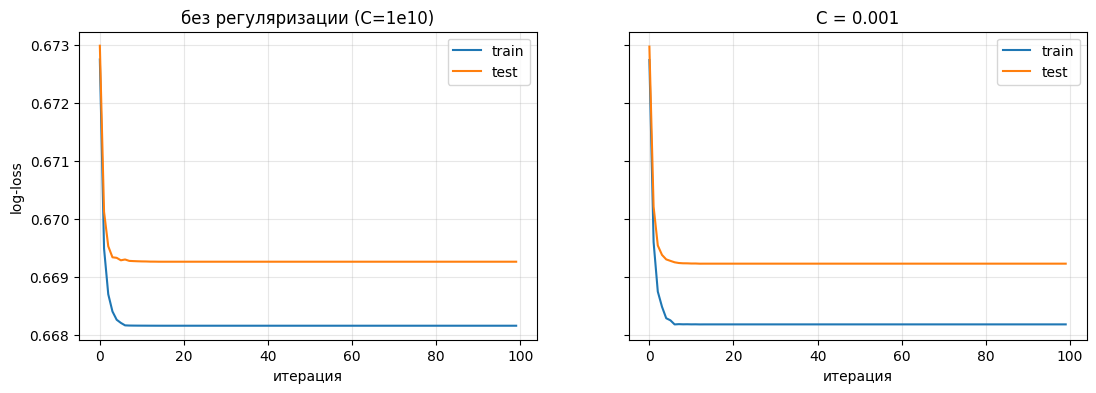

In [15]:
def loss_curves(n_iter=100, **kw):
    clf = LogisticRegression(max_iter=1, warm_start=True, solver='lbfgs', **kw)
    tr, te = [], []
    for _ in range(n_iter):
        clf.fit(X_train_s, y_train)
        tr.append(log_loss(y_train, clf.predict_proba(X_train_s)))
        te.append(log_loss(y_test, clf.predict_proba(X_test_s)))
    return tr, te

curves = {'без регуляризации (C=1e10)': loss_curves(C=1e10),
          'C = 0.001': loss_curves(C=1e-3)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True, sharey=True)
for ax, (name, (tr, te)) in zip(axes, curves.items()):
    ax.plot(tr, label='train'); ax.plot(te, label='test')
    ax.set_title(name); ax.set_xlabel('итерация'); ax.legend(); ax.grid(alpha=.3)
axes[0].set_ylabel('log-loss')
plt.show()

__Выводы:__

## Часть 2. Работа с категориальными переменными

В этой части мы научимся обрабатывать категориальные переменные, так как закодировать их в виде чисел недостаточно (это задаёт некоторый порядок, которого на категориальных переменных может и не быть). Существует два основных способа обработки категориальных значений:
- One-hot-кодирование
- Счётчики (CTR, mean-target кодирование, ...) — каждый категориальный признак заменяется на среднее значение целевой переменной по всем объектам, имеющим одинаковое значение в этом признаке.

Начнём с one-hot-кодирования. Допустим наш категориальный признак $f_j(x)$ принимает значения из множества $C=\{c_1, \dots, c_m\}$. Заменим его на $m$ бинарных признаков $b_1(x), \dots, b_m(x)$, каждый из которых является индикатором одного из возможных категориальных значений:
$$
b_i(x) = [f_j(x) = c_i]
$$

__Задание 1.__ Закодируйте все категориальные признаки с помощью one-hot-кодирования. Обучите логистическую регрессию и посмотрите, как изменилось качество модели (с тем, что было ранее). Измерьте время, потребовавшееся на обучение модели.

__(3 балла)__

Как можно было заменить, one-hot-кодирование может сильно увеличивать количество признаков в датасете, что сказывается на памяти, особенно, если некоторый признак имеет большое количество значений. Эту проблему решает другой способ кодирование категориальных признаков — счётчики. Основная идея в том, что нам важны не сами категории, а значения целевой переменной, которые имеют объекты этой категории. Каждый категориальный признак мы заменим средним значением целевой переменной по всем объектам этой же категории:
$$
g_j(x, X) = \frac{\sum_{i=1}^{l} [f_j(x) = f_j(x_i)][y_i = +1]}{\sum_{i=1}^{l} [f_j(x) = f_j(x_i)]}
$$

__Задание 2.__ Закодируйте категориальные переменные с помощью счётчиков (ровно так, как описано выше без каких-либо хитростей). Обучите логистическую регрессию и посмотрите на качество модели на тестовом множестве. Сравните время обучения с предыдущим экспериментов. Заметили ли вы что-то интересное?

__(2 балла)__

__Вывод:__

Отметим, что такие признаки сами по себе являются классификаторами и, обучаясь на них, мы допускаем "утечку" целевой переменной в признаки. Это ведёт к переобучению, поэтому считать такие признаки необходимо таким образом, чтобы при вычислении для конкретного объекта его целевая метка не использовалась. Это можно делать следующими способами:
- вычислять значение счётчика по всем объектам расположенным выше в датасете (например, если у нас выборка отсортирована по времени)
- вычислять по фолдам, то есть делить выборку на некоторое количество частей и подсчитывать значение признаков по всем фолдам кроме текущего (как делается в кросс-валидации)
- внесение некоторого шума в посчитанные признаки (необходимо соблюсти баланс между избавление от переобучения и полезностью признаков).

__Задание 3.__ Реализуйте корректное вычисление счётчиков двумя из трех вышеперчисленных способов, сравните. Снова обучите логистическую регрессию, оцените качество. Сделайте выводы.

__(3 балла)__

__Вывод:__